# 01. Offline Baseline & Operating Zones (F.E. Walter Dam)

- **Goal:** Verify mass-balance closure and expose how a seasonal-blind rule drifts from pool targets.
- **Case & Window:** Francis E. Walter Dam (`2021`, `365` daily steps).
- **Pass Criterion:** `verify_run = PASS`, zero network calls, closure error near machine precision.

*Runs 100% offline inside a temporary directory (`0` API cost).*

In [1]:
from pathlib import Path
import sys, tempfile
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Check Operating Zones Before Running

Plot `elevation_storage.csv` with seasonal conservation (`1,300 ft`), recreation (`1,370 ft`), spillway crest (`1,450 ft`), and outlet limit (`10,000 cfs`).

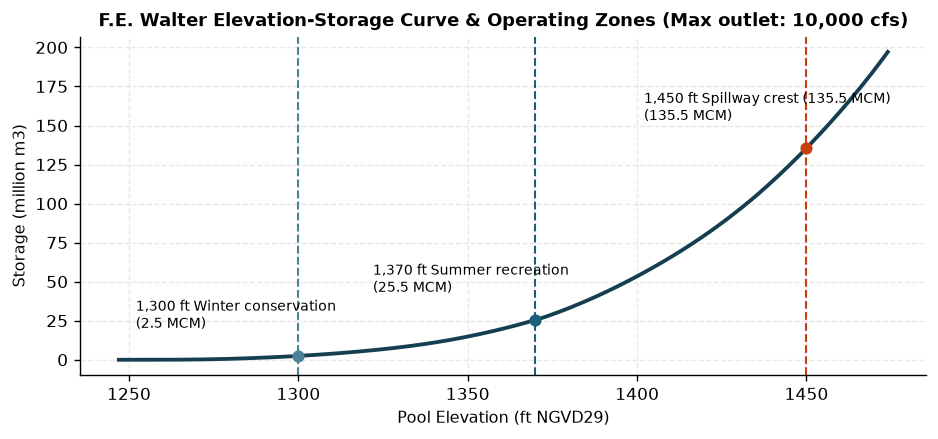

In [2]:
elev_ft, storage_m3, _ = h.load_fe_walter_curve(REPO_ROOT)
storage_mcm = storage_m3 / 1.0e6
fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.plot(elev_ft, storage_mcm, color=C["navy"], lw=2.2, label="Rating curve (ac-ft -> m3)")
for lvl, col, lbl in [
    (1300, C["slate"], "1,300 ft Winter conservation"),
    (1370, C["teal"], "1,370 ft Summer recreation"),
    (1450, C["coral"], "1,450 ft Spillway crest (135.5 MCM)"),
]:
    vol = float(np.interp(lvl, elev_ft, storage_mcm))
    ax.axvline(lvl, color=col, ls="--", lw=1.2)
    ax.scatter([lvl], [vol], color=col, zorder=5)
    ax.annotate(f"{lbl}\n({vol:.1f} MCM)", xy=(lvl, vol), xytext=(lvl - 48, vol + 18), fontsize=8)
ax.set_xlabel("Pool Elevation (ft NGVD29)"); ax.set_ylabel("Storage (million m3)")
ax.set_title("F.E. Walter Elevation-Storage Curve & Operating Zones (Max outlet: 10,000 cfs)")
plt.tight_layout(); plt.show()

## 2. Run 2021 Hanasaki Baseline & Verify Offline

- Executes `rule_based.yaml` (`alpha = 0.85`, offline) inside `TemporaryDirectory()`.
- Audits mass balance, timestamps, and routing via `verify_run(..., require_offline=True)`.

In [3]:
with tempfile.TemporaryDirectory() as td:
    m01 = h.run_fe_walter_2021_rule(REPO_ROOT, Path(td))

traj, obs, ver = m01["trajectory"], m01["observations"], m01["verification"]
res_max = float(traj["mass_balance_residual_m3"].abs().max())
sc_lvl = h.kge_components(traj["elevation_ft"], obs["water_level_ft"])
sc_rel = h.kge_components(traj["release_cfs"], obs["release_cfs"])
print(f"verify_run : {ver['status']} | observed_network_calls = {ver['observed_network_calls']} | steps = {len(traj)}")
print(f"Max |residual| : {res_max:.2e} m3 | Final storage: {traj['storage_end_m3'].iloc[-1]:,.0f} m3")
print(f"2021 vs USGS   : Level KGE={sc_lvl['kge']:.3f} (RMSE={sc_lvl['rmse']:.1f} ft) | Release KGE={sc_rel['kge']:.3f}")


verify_run : PASS | observed_network_calls = 0 | steps = 365
Max |residual| : 0.00e+00 m3 | Final storage: 115,202,924 m3
2021 vs USGS   : Level KGE=0.193 (RMSE=79.0 ft) | Release KGE=0.478


## 3. Does Hanasaki Hold Seasonal Targets?

Compare simulated elevation against faint USGS `01447780` observations to see why fixed rules fail seasonal recreation refill.

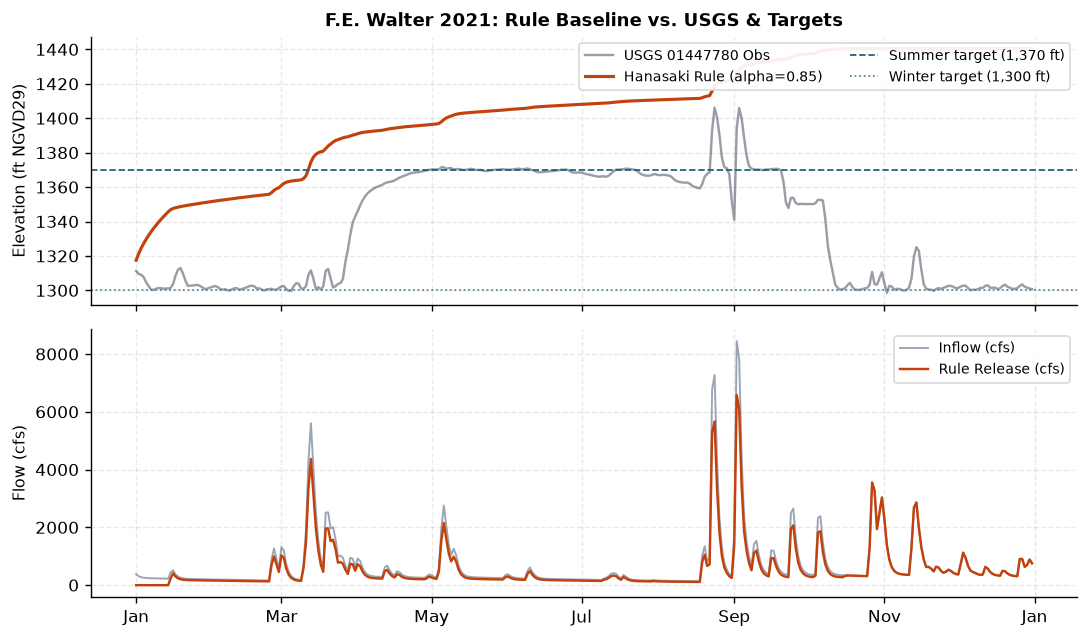

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.8, 5.2), sharex=True)
ax1.plot(obs["date_dt"], obs["water_level_ft"], color=C["obs"], alpha=0.45, lw=1.4, label="USGS 01447780 Obs")
ax1.plot(traj["date_dt"], traj["elevation_ft"], color=C["coral"], lw=1.8, label="Hanasaki Rule (alpha=0.85)")
ax1.axhline(1370, color=C["teal"], ls="--", lw=1.0, label="Summer target (1,370 ft)")
ax1.axhline(1300, color=C["slate"], ls=":", lw=1.0, label="Winter target (1,300 ft)")
ax1.set_ylabel("Elevation (ft NGVD29)"); ax1.set_title("F.E. Walter 2021: Rule Baseline vs. USGS & Targets")
ax1.legend(loc="upper right", ncol=2, fontsize=8)

ax2.plot(traj["date_dt"], traj["inflow_cfs"], color=C["muted"], alpha=0.65, lw=1.1, label="Inflow (cfs)")
ax2.plot(traj["date_dt"], traj["release_cfs"], color=C["coral"], lw=1.4, label="Rule Release (cfs)")
ax2.set_ylabel("Flow (cfs)"); ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

- **Mass balance:** Residual stays near machine epsilon across all 365 days.
- **Seasonal drift:** Fixed rules ignore April–May refill (`1,370 ft`), motivating LLM control in Module 02.
- **Bound note:** `rule_case.json` sets `0` min release; M02's `case.json` sets `50 cfs`.

## 4. Adapt to Your Basin

- **Dam (`case.json`):** Set storage/release limits (`m3`, `m3/s`), `8.0e+6` syntax, UH sum `= 1.0`.
- **Inflows (`inflows.csv`):** Supply incremental subbasin inflows only.
- **Rule (`rule_based.yaml`):** Point `strategy: benchmark` to your statistics JSON.

Next: [Module 02](../02_prompt_and_knowledge_design/02_llm_prompt_and_knowledge.ipynb)